In [1]:
from scipy.io import loadmat
import mat73

from tqdm.notebook import tqdm
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib import colorbar as mbar
import seaborn as sns

from scipy.ndimage import gaussian_filter as smooth

from scipy.stats import permutation_test

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import confusion_matrix as ConMat

from sklearn.metrics.pairwise import cosine_similarity as cosine
from sklearn.metrics.pairwise import euclidean_distances as eu_dist
from scipy.linalg import subspace_angles as angle

from sklearn.utils import shuffle

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

## Definitions ##

In [2]:
def m_plot(input_data, colors, error_method='sem', smooth_win=0, labels=[], plot_title='', XAxisTicks=[], figure_size=(8,3)):
    '''
    Args:
        input_data:   (N,M,T) matrix of input data, (Conditions,Samples,Timepoints)
        colors:       (N,4) matrix of colors for the generated plots in [R,G,B,FaceAlpha] format,
                      where N is the number of conditions. FaceAlpha in the scale=[0-255]
        error_method: variation metric ('sem' & 'std')
        smooth_win:   smoothing window
        
        labels:       (N,) list of labels for the generated plots, where N is the number of conditions
        plot_title:   title of the generated plot
        XAxisTicks:   (N,) vaetor of XAxisTicks
        figure_size:  two-item tuple containing width and height of the figure
    Returns:
        none
    '''

    colors = np.array(colors) / np.array(255)
    if not labels: labels=['']*len(input_data)
    XAxisTicks = np.array(XAxisTicks)
    if XAxisTicks.size==0: XAxisTicks = np.arange(0,input_data[0].shape[1])
    
    plt.figure(figsize=figure_size)
    for i,Cond in enumerate(input_data):
        data_ave = smooth(np.nanmean(Cond, axis=0), smooth_win)
        data_std = smooth(np.nanstd(Cond, axis=0), smooth_win)
        
        if error_method=='sem':
            error_up  = data_ave + (data_std / np.sqrt(Cond.shape[0]))
            error_low = data_ave - (data_std / np.sqrt(Cond.shape[0]))
        elif error_method=='std':
            error_up  = data_ave + data_std
            error_low = data_ave - data_std

        plt.fill_between(XAxisTicks, error_up, error_low, color=colors[i], label='_nolegend_')
        plt.plot(XAxisTicks, data_ave, color=colors[i,:3], lw=figure_size[0]*.5, label=labels[i])
    
    ylim = plt.ylim()
    plt.legend(frameon=False, fontsize=figure_size[0]*1.5)
    plt.title(plot_title, fontsize=figure_size[0]*1.8)
    # plt.rcParams.update({'font.size': figure_size[0]*.5})
    plt.tight_layout()
    

def L1L2_Sparsity(data_arr):
    '''
    Args:
        data_arr: (N,) vector of data
    Returns:
        sparsity value
    '''

    l1_norm = np.sum(np.abs((data_arr)))
    l2_norm = np.sqrt(np.sum((data_arr**2)))
    return (l1_norm / l2_norm) / len(data_arr)


def comp_permute_p(vec1, vec2, permute_reps=100001):
    '''
    Args:
        vec1:         (N,) vector of data 1st distribution (Samples,)
        vec2:         (N,) vector of data 2nd distribution (Samples,)
        permute_reps: number of repetitions for the permutation process
    Returns:
        p_val: two-tailed p-value of the permutation process for [vec2 - vec1]
    '''

    vec1 = vec1[np.where((~np.isnan(vec1)))[0]]
    vec2 = vec2[np.where((~np.isnan(vec2)))[0]]

    def tmp_test_stat(x, y, axis):
        return np.nanmean(x, axis=axis) - np.nanmean(y, axis=axis)
    
    p_val = np.nan
    p_val = permutation_test(data=(vec2, vec1), statistic=tmp_test_stat, vectorized=True, axis=0, random_state=15, n_resamples=permute_reps).pvalue

    return p_val


def compute_dprime(data1, data2):
    '''
    Args:
        data1: data for condition 1, shape (N,)
        data2: data for condition 2, shape (N,)
    Returns:
        d-prime value between the two data distributions, for data1-data2
    '''
    
    return (np.nanmean(data1) - np.nanmean(data2)) / np.sqrt(.5 * (np.nanvar(data1) + np.nanvar(data2)) )


# Load Data


In [4]:
FigDir = '../Results/figs_ml/'

tmp_FileDir = '../Results/results/YMT_Power_v01_zscore.mat'
tmp_File = mat73.loadmat(tmp_FileDir)

chn_ob, chn_mpfc = 0, 1
regions = ['OB', 'mPFC']
fbands = ['Delta', 'Theta', 'Beta']

freqs = tmp_File['ff']
power_b = tmp_File['baseline_correcected_power_baseline']
power_w = tmp_File['baseline_correcected_power_wrong']
power_c = tmp_File['baseline_correcected_power_correct']

idx_band_delta = np.where((freqs<=4))[0]
idx_band_theta = np.where((freqs>4) & (freqs<=12))[0]
idx_band_beta = np.where((freqs>12))[0]

# color
color_ob, color_mpfc = [163, 29, 29, 80], [117, 75, 125, 80]
color_ob_n, color_mpfc_n = np.array(color_ob[:3])/255, np.array(color_mpfc[:3])/255
color_b, color_w, color_c = [100, 100, 100, 80], [222, 49, 99, 80], [50, 142, 110, 80]
color_b_n, color_w_n, color_c_n = np.array(color_b[:3])/255, np.array(color_w[:3])/255, np.array(color_c[:3])/255

num_chn, num_conds, num_max_tr = len(regions), 3, np.max([power_b.shape[1], power_w.shape[1], power_c.shape[1]])

# parameters
trn_por = .7
tst_por = 1 - trn_por
chance_level = 50
cycle_num = 200

power_wc = np.concatenate((power_w,power_c), axis=1)
idx_wc = np.concatenate((np.ones(power_w.shape[1])*1,np.ones(power_c.shape[1])*2), axis=0)
power_bt = np.concatenate((power_b,power_w,power_c), axis=1)
idx_bt = np.concatenate((np.ones(power_b.shape[1])*1,np.ones(power_w.shape[1])*2,np.ones(power_c.shape[1])*2), axis=0)


# Classifier: C vs. W

In [5]:
np.random.seed(15)

# initialize arrays for performance
acc_ob_wc = np.zeros(cycle_num) * np.nan
acc_ob_shuff_wc, acc_mpfc_wc, acc_mpfc_shuff_wc = np.copy(acc_ob_wc), np.copy(acc_ob_wc), np.copy(acc_ob_wc)

# initialize arrays for frequency weights
freqwt_ob_wc = np.zeros((cycle_num, freqs.shape[0])) * np.nan
freqwt_ob_shuff_wc, freqwt_mpfc_wc, freqwt_mpfc_shuff_wc = np.copy(freqwt_ob_wc), np.copy(freqwt_ob_wc), np.copy(freqwt_ob_wc)

for iCycle in tqdm(range(cycle_num)):
    X_trn, X_tst, y_trn, y_tst = tts(power_wc[chn_ob,:,:], idx_wc, test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_ob_wc[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_ob_wc[iCycle] = tmp_lda_mdl.coef_[0]

    X_trn, X_tst, y_trn, y_tst = tts(power_wc[chn_ob,:,:], shuffle(idx_wc), test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_ob_shuff_wc[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_ob_shuff_wc[iCycle] = tmp_lda_mdl.coef_[0]

    X_trn, X_tst, y_trn, y_tst = tts(power_wc[chn_mpfc,:,:], idx_wc, test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_mpfc_wc[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_mpfc_wc[iCycle] = tmp_lda_mdl.coef_[0]

    X_trn, X_tst, y_trn, y_tst = tts(power_wc[chn_mpfc,:,:], shuffle(idx_wc), test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_mpfc_shuff_wc[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_mpfc_shuff_wc[iCycle] = tmp_lda_mdl.coef_[0]


  0%|          | 0/200 [00:00<?, ?it/s]

OB Acc. (mean -+ sd) | Data: 51.38 -+ 6.09
OB Acc. (mean -+ sd) | Shuffled 49.3 -+ 7.25
OB Permutation p-val: 0.0025399492010159796
OB Permutation d-prime: 0.3107230616875998
mPFC Acc. (mean -+ sd) | Data: 49.8 -+ 5.15
mPFC Acc. (mean -+ sd) | Shuffled 49.18 -+ 5.54
mPFC Permutation p-val: 0.24861502769944602
mPFC Permutation d-prime: 0.1159813508661346


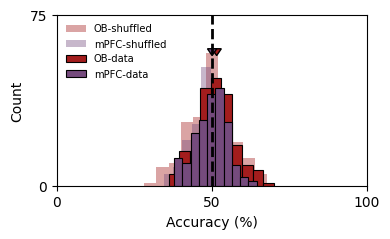

In [12]:
plot_xticks = [0,50,100]
plot_xlim = [0,100]
plot_ylim = [0,75]
plot_trans = 1
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
fig_lw = figure_size[0]*.5
save_fig = 0

plt.figure(figsize=figure_size)

plt.hist(acc_ob_shuff_wc, color=color_ob_n, alpha=plot_trans-.6, label='OB-shuffled')
plt.hist(acc_mpfc_shuff_wc, color=color_mpfc_n, alpha=plot_trans-.6, label='mPFC-shuffled')

plt.hist(acc_ob_wc, color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='OB-data')
plt.hist(acc_mpfc_wc, color=color_mpfc_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='mPFC-data')

plt.arrow(np.nanmedian(acc_ob_wc), 60, 0, -.0001, head_length=3, head_width=3, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(acc_mpfc_wc), 60, 0, -.0001, head_length=3, head_width=3, ec=plot_edgecolor, color=color_mpfc_n)

plt.axvline(chance_level, lw=fig_lw, color='k', ls='--')

plt.xlim(plot_xlim)
plt.xticks(plot_xticks)
plt.xlabel('Accuracy (%)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper left', fontsize=figure_size[0]*1.8)
clear_output()

print(f"OB Acc. (mean -+ sd) | Data: {np.nanmean(acc_ob_wc).round(2)} -+ {np.nanstd(acc_ob_wc).round(2)}")
print(f"OB Acc. (mean -+ sd) | Shuffled {np.nanmean(acc_ob_shuff_wc).round(2)} -+ {np.nanstd(acc_ob_shuff_wc).round(2)}")
print(f"OB Permutation p-val: {comp_permute_p(acc_ob_wc, acc_ob_shuff_wc)}")
print(f"OB Permutation d-prime: {compute_dprime(acc_ob_wc, acc_ob_shuff_wc)}")
print(f'===========')
print(f"mPFC Acc. (mean -+ sd) | Data: {np.nanmean(acc_mpfc_wc).round(2)} -+ {np.nanstd(acc_mpfc_wc).round(2)}")
print(f"mPFC Acc. (mean -+ sd) | Shuffled {np.nanmean(acc_mpfc_shuff_wc).round(2)} -+ {np.nanstd(acc_mpfc_shuff_wc).round(2)}")
print(f"mPFC Permutation p-val: {comp_permute_p(acc_mpfc_wc, acc_mpfc_shuff_wc)}")
print(f"mPFC Permutation d-prime: {compute_dprime(acc_mpfc_wc, acc_mpfc_shuff_wc)}")

if save_fig: plt.savefig(f'{FigDir}power_ml_wc.svg')

In [6]:
ave_freqwt_wc = np.zeros((num_chn,num_conds,cycle_num)) * np.nan
ave_freqwt_wc_shuff = np.copy(ave_freqwt_wc)

ave_freqwt_wc[chn_ob,0] = abs(freqwt_ob_wc[:,idx_band_delta].mean(axis=1))
ave_freqwt_wc[chn_ob,1] = abs(freqwt_ob_wc[:,idx_band_theta].mean(axis=1))
ave_freqwt_wc[chn_ob,2] = abs(freqwt_ob_wc[:,idx_band_beta].mean(axis=1))

ave_freqwt_wc[chn_mpfc,0] = abs(freqwt_mpfc_wc[:,idx_band_delta].mean(axis=1))
ave_freqwt_wc[chn_mpfc,1] = abs(freqwt_mpfc_wc[:,idx_band_theta].mean(axis=1))
ave_freqwt_wc[chn_mpfc,2] = abs(freqwt_mpfc_wc[:,idx_band_beta].mean(axis=1))

ave_freqwt_wc_shuff[chn_ob,0] = abs(freqwt_ob_shuff_wc[:,idx_band_delta].mean(axis=1))
ave_freqwt_wc_shuff[chn_ob,1] = abs(freqwt_ob_shuff_wc[:,idx_band_theta].mean(axis=1))
ave_freqwt_wc_shuff[chn_ob,2] = abs(freqwt_ob_shuff_wc[:,idx_band_beta].mean(axis=1))

ave_freqwt_wc_shuff[chn_mpfc,0] = abs(freqwt_mpfc_shuff_wc[:,idx_band_delta].mean(axis=1))
ave_freqwt_wc_shuff[chn_mpfc,1] = abs(freqwt_mpfc_shuff_wc[:,idx_band_theta].mean(axis=1))
ave_freqwt_wc_shuff[chn_mpfc,2] = abs(freqwt_mpfc_shuff_wc[:,idx_band_beta].mean(axis=1))

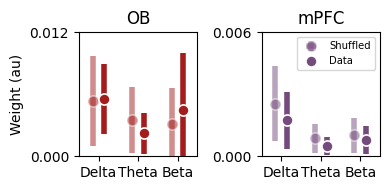

In [7]:
plot_xticks = ['Delta', 'Theta', 'Beta']
plot_trans = 1
plot_xlim = [-.5,2.5]
figure_size = np.array((2,1)) * 2
plot_bar_thickness = .5 # figure_size[0]*.06
plot_err_lw = figure_size[0]*1
plot_err_ms = figure_size[0]*4
plot_edge_lw = figure_size[0]*1.6
plot_edge_markerw = figure_size[0]*.3
grp_dist = .15
save_fig = 0

fig, axs = plt.subplots(figsize=figure_size, ncols=2, nrows=1, sharex=True)

sel_chn = chn_ob
axs[0].errorbar(np.arange(ave_freqwt_wc_shuff.shape[1]) -grp_dist, np.nanmean(ave_freqwt_wc_shuff[sel_chn],axis=1)
                , xerr=0, yerr=np.nanstd(ave_freqwt_wc_shuff[sel_chn],axis=1)
                , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
                , elinewidth=plot_err_lw, color=color_ob_n, alpha=plot_trans-.5, label='Shuffled')

axs[0].errorbar(np.arange(ave_freqwt_wc.shape[1]) +grp_dist, np.nanmean(ave_freqwt_wc[sel_chn],axis=1)
             , xerr=0, yerr=np.nanstd(ave_freqwt_wc[sel_chn],axis=1)
             , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
             , elinewidth=plot_err_lw, color=color_ob_n, alpha=plot_trans, label='Data')
axs[0].set_ylim([0,.012])
axs[0].set_yticks([0,.012])
axs[0].set_xticks(np.arange(ave_freqwt_wc.shape[1]), plot_xticks)
axs[0].set_title(f'{regions[sel_chn]}')

sel_chn = chn_mpfc
axs[1].errorbar(np.arange(ave_freqwt_wc_shuff.shape[1]) -grp_dist, np.nanmean(ave_freqwt_wc_shuff[sel_chn],axis=1)
                , xerr=0, yerr=np.nanstd(ave_freqwt_wc_shuff[sel_chn],axis=1)
                , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
                , elinewidth=plot_err_lw, color=color_mpfc_n, alpha=plot_trans-.5, label='Shuffled')

axs[1].errorbar(np.arange(ave_freqwt_wc.shape[1]) +grp_dist, np.nanmean(ave_freqwt_wc[sel_chn],axis=1)
             , xerr=0, yerr=np.nanstd(ave_freqwt_wc[sel_chn],axis=1)
             , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
             , elinewidth=plot_err_lw, color=color_mpfc_n, alpha=plot_trans, label='Data')
axs[1].set_ylim([0,.006])
axs[1].set_yticks([0,.006])
axs[1].set_title(f'{regions[sel_chn]}')

axs[0].set_xlim(plot_xlim)
axs[0].set_xticks(np.arange(ave_freqwt_wc.shape[1]), plot_xticks)
axs[0].set_ylabel('Weight (au)')

axs[1].legend(['Shuffled', 'Data'], frameon=True, ncol=1, fontsize=figure_size[0]*1.8)

plt.tight_layout()
if save_fig: plt.savefig(f'{FigDir}power_ml_freqwt_wc.svg')

In [8]:
for iReg,reg in enumerate(regions):
    for iBand,band in enumerate(fbands):
        print(f'{reg} {band} -> p-value: {comp_permute_p(ave_freqwt_wc[iReg,iBand], ave_freqwt_wc_shuff[iReg,iBand])} | d-prime: {compute_dprime(ave_freqwt_wc[iReg,iBand], ave_freqwt_wc_shuff[iReg,iBand])}')
    print('------------')

OB Delta -> p-value: 0.6666466670666586 | d-prime: 0.04226392961017259
OB Theta -> p-value: 1.999960000799984e-05 | d-prime: -0.47718780977166975
OB Beta -> p-value: 0.0013999720005599889 | d-prime: 0.31352059573236185
------------
mPFC Delta -> p-value: 3.999920001599968e-05 | d-prime: -0.5054560744525499
mPFC Theta -> p-value: 1.999960000799984e-05 | d-prime: -0.6726771320439393
mPFC Beta -> p-value: 0.00879982400351993 | d-prime: -0.263483875750065
------------


In [9]:
sparsity_wc = np.zeros((num_chn,cycle_num)) * np.nan
sparsity_wc_shuff = np.copy(sparsity_wc)

for iCycle in range(cycle_num):
    sparsity_wc[chn_ob, iCycle]   = L1L2_Sparsity(freqwt_ob_wc[iCycle])
    sparsity_wc[chn_mpfc, iCycle] = L1L2_Sparsity(freqwt_mpfc_wc[iCycle])

    sparsity_wc_shuff[chn_ob, iCycle]   = L1L2_Sparsity(freqwt_ob_shuff_wc[iCycle])
    sparsity_wc_shuff[chn_mpfc, iCycle] = L1L2_Sparsity(freqwt_mpfc_shuff_wc[iCycle])

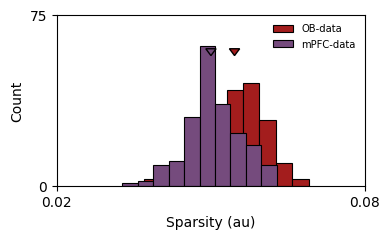

In [10]:
plot_xlim = [.02,.08]
plot_ylim = [0,75]
plot_trans = 1
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
fig_lw = figure_size[0]*.5
save_fig = 0

plt.figure(figsize=figure_size)

# plt.hist(sparsity_wc_shuff[chn_ob], color=color_ob_n, alpha=plot_trans-.6, label='OB-shuffled')
# plt.hist(sparsity_wc_shuff[chn_mpfc], color=color_mpfc_n, alpha=plot_trans-.6, label='mPFC-shuffled')

plt.hist(sparsity_wc[chn_ob], color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='OB-data')
plt.hist(sparsity_wc[chn_mpfc], color=color_mpfc_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='mPFC-data')

plt.arrow(np.nanmedian(sparsity_wc[chn_ob]), 60, 0, -.0001, head_length=3, head_width=.002, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(sparsity_wc[chn_mpfc]), 60, 0, -.0001, head_length=3, head_width=.002, ec=plot_edgecolor, color=color_mpfc_n)

plt.xlim(plot_xlim)
plt.xticks(plot_xlim)
plt.xlabel('Sparsity (au)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper right', fontsize=figure_size[0]*1.8)
clear_output()

if save_fig: plt.savefig(f'{FigDir}power_ml_sparsity_wc.svg')

# Classifier: Baseline vs. Task

In [11]:
np.random.seed(15)

# initialize arrays for performance
acc_ob_bt = np.zeros(cycle_num) * np.nan
acc_mpfc_bt, acc_ob_shuff_bt, acc_mpfc_shuff_bt = np.copy(acc_ob_bt), np.copy(acc_ob_bt), np.copy(acc_ob_bt)

# initialize arrays for frequency weights
freqwt_ob_bt = np.zeros((cycle_num, freqs.shape[0])) * np.nan
freqwt_ob_shuff_bt, freqwt_mpfc_bt, freqwt_mpfc_shuff_bt = np.copy(freqwt_ob_bt), np.copy(freqwt_ob_bt), np.copy(freqwt_ob_bt)

for iCycle in tqdm(range(cycle_num)):
    X_trn, X_tst, y_trn, y_tst = tts(power_bt[chn_ob,:,:], idx_bt, test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_ob_bt[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_ob_bt[iCycle] = tmp_lda_mdl.coef_[0]

    X_trn, X_tst, y_trn, y_tst = tts(power_bt[chn_ob,:,:], shuffle(idx_bt), test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_ob_shuff_bt[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_ob_shuff_bt[iCycle] = tmp_lda_mdl.coef_[0]

    X_trn, X_tst, y_trn, y_tst = tts(power_bt[chn_mpfc,:,:], idx_bt, test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_mpfc_bt[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_mpfc_bt[iCycle] = tmp_lda_mdl.coef_[0]

    X_trn, X_tst, y_trn, y_tst = tts(power_bt[chn_mpfc,:,:], shuffle(idx_bt), test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_mpfc_shuff_bt[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_mpfc_shuff_bt[iCycle] = tmp_lda_mdl.coef_[0]


  0%|          | 0/200 [00:00<?, ?it/s]

OB Acc. (mean -+ sd) | Data: 84.49 -+ 3.91
OB Acc. (mean -+ sd) | Shuffled 49.56 -+ 4.84
OB Permutation p-val: 1.999960000799984e-05
OB Permutation d-prime: 7.940212985629012
mPFC Acc. (mean -+ sd) | Data: 63.62 -+ 8.24
mPFC Acc. (mean -+ sd) | Shuffled 49.71 -+ 3.07
mPFC Permutation p-val: 1.999960000799984e-05
mPFC Permutation d-prime: 2.2364673836395847


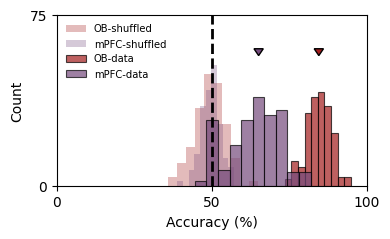

In [12]:
plot_xticks = [0,50,100]
plot_xlim = [0,100]
plot_ylim = [0,75]
plot_trans = .7
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
fig_lw = figure_size[0]*.5
save_fig = 0

plt.figure(figsize=figure_size)

plt.hist(acc_ob_shuff_bt, color=color_ob_n, alpha=plot_trans-.4, label='OB-shuffled')
plt.hist(acc_mpfc_shuff_bt, color=color_mpfc_n, alpha=plot_trans-.4, label='mPFC-shuffled')

plt.hist(acc_ob_bt, color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='OB-data')
plt.hist(acc_mpfc_bt, color=color_mpfc_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='mPFC-data')

plt.arrow(np.nanmedian(acc_ob_bt), 60, 0, -.0001, head_length=3, head_width=3, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(acc_mpfc_bt), 60, 0, -.0001, head_length=3, head_width=3, ec=plot_edgecolor, color=color_mpfc_n)

plt.axvline(chance_level, lw=fig_lw, color='k', ls='--')

plt.xlim(plot_xlim)
plt.xticks(plot_xticks)
plt.xlabel('Accuracy (%)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper left', fontsize=figure_size[0]*1.8)
clear_output()

print(f"OB Acc. (mean -+ sd) | Data: {np.nanmean(acc_ob_bt).round(2)} -+ {np.nanstd(acc_ob_bt).round(2)}")
print(f"OB Acc. (mean -+ sd) | Shuffled {np.nanmean(acc_ob_shuff_bt).round(2)} -+ {np.nanstd(acc_ob_shuff_bt).round(2)}")
print(f"OB Permutation p-val: {comp_permute_p(acc_ob_bt, acc_ob_shuff_bt)}")
print(f"OB Permutation d-prime: {compute_dprime(acc_ob_bt, acc_ob_shuff_bt)}")
print(f'===========')
print(f"mPFC Acc. (mean -+ sd) | Data: {np.nanmean(acc_mpfc_bt).round(2)} -+ {np.nanstd(acc_mpfc_bt).round(2)}")
print(f"mPFC Acc. (mean -+ sd) | Shuffled {np.nanmean(acc_mpfc_shuff_bt).round(2)} -+ {np.nanstd(acc_mpfc_shuff_bt).round(2)}")
print(f"mPFC Permutation p-val: {comp_permute_p(acc_mpfc_bt, acc_mpfc_shuff_bt)}")
print(f"mPFC Permutation d-prime: {compute_dprime(acc_mpfc_bt, acc_mpfc_shuff_bt)}")

if save_fig: plt.savefig(f'{FigDir}power_ml_bt.svg')

In [13]:
ave_freqwt_bt = np.zeros((num_chn,num_conds,cycle_num)) * np.nan
ave_freqwt_bt_shuff = np.copy(ave_freqwt_bt)

ave_freqwt_bt[chn_ob,0] = abs(freqwt_ob_bt[:,idx_band_delta].mean(axis=1))
ave_freqwt_bt[chn_ob,1] = abs(freqwt_ob_bt[:,idx_band_theta].mean(axis=1))
ave_freqwt_bt[chn_ob,2] = abs(freqwt_ob_bt[:,idx_band_beta].mean(axis=1))

ave_freqwt_bt[chn_mpfc,0] = abs(freqwt_mpfc_bt[:,idx_band_delta].mean(axis=1))
ave_freqwt_bt[chn_mpfc,1] = abs(freqwt_mpfc_bt[:,idx_band_theta].mean(axis=1))
ave_freqwt_bt[chn_mpfc,2] = abs(freqwt_mpfc_bt[:,idx_band_beta].mean(axis=1))

ave_freqwt_bt_shuff[chn_ob,0] = abs(freqwt_ob_shuff_bt[:,idx_band_delta].mean(axis=1))
ave_freqwt_bt_shuff[chn_ob,1] = abs(freqwt_ob_shuff_bt[:,idx_band_theta].mean(axis=1))
ave_freqwt_bt_shuff[chn_ob,2] = abs(freqwt_ob_shuff_bt[:,idx_band_beta].mean(axis=1))

ave_freqwt_bt_shuff[chn_mpfc,0] = abs(freqwt_mpfc_shuff_bt[:,idx_band_delta].mean(axis=1))
ave_freqwt_bt_shuff[chn_mpfc,1] = abs(freqwt_mpfc_shuff_bt[:,idx_band_theta].mean(axis=1))
ave_freqwt_bt_shuff[chn_mpfc,2] = abs(freqwt_mpfc_shuff_bt[:,idx_band_beta].mean(axis=1))

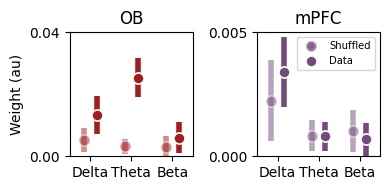

In [14]:
plot_xticks = ['Delta', 'Theta', 'Beta']
plot_trans = 1
plot_xlim = [-.5,2.5]
figure_size = np.array((2,1)) * 2
plot_bar_thickness = .5 # figure_size[0]*.06
plot_err_lw = figure_size[0]*1
plot_err_ms = figure_size[0]*4
plot_edge_lw = figure_size[0]*1.6
plot_edge_markerw = figure_size[0]*.3
grp_dist = .15
save_fig = 0

fig, axs = plt.subplots(figsize=figure_size, ncols=2, nrows=1, sharex=True) #, sharey=True)

sel_chn = chn_ob
axs[0].errorbar(np.arange(ave_freqwt_bt_shuff.shape[1]) -grp_dist, np.nanmean(ave_freqwt_bt_shuff[sel_chn],axis=1)
                , xerr=0, yerr=np.nanstd(ave_freqwt_bt_shuff[sel_chn],axis=1)
                , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
                , elinewidth=plot_err_lw, color=color_ob_n, alpha=plot_trans-.5, label='Shuffled')

axs[0].errorbar(np.arange(ave_freqwt_bt.shape[1]) +grp_dist, np.nanmean(ave_freqwt_bt[sel_chn],axis=1)
             , xerr=0, yerr=np.nanstd(ave_freqwt_bt[sel_chn],axis=1)
             , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
             , elinewidth=plot_err_lw, color=color_ob_n, alpha=plot_trans, label='Data')
axs[0].set_ylim([0,.04])
axs[0].set_yticks([0,.04])
axs[0].set_title(f'{regions[sel_chn]}')

sel_chn = chn_mpfc
axs[1].errorbar(np.arange(ave_freqwt_bt_shuff.shape[1]) -grp_dist, np.nanmean(ave_freqwt_bt_shuff[sel_chn],axis=1)
                , xerr=0, yerr=np.nanstd(ave_freqwt_bt_shuff[sel_chn],axis=1)
                , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
                , elinewidth=plot_err_lw, color=color_mpfc_n, alpha=plot_trans-.5, label='Shuffled')

axs[1].errorbar(np.arange(ave_freqwt_bt.shape[1]) +grp_dist, np.nanmean(ave_freqwt_bt[sel_chn],axis=1)
             , xerr=0, yerr=np.nanstd(ave_freqwt_bt[sel_chn],axis=1)
             , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
             , elinewidth=plot_err_lw, color=color_mpfc_n, alpha=plot_trans, label='Data')
axs[1].set_ylim([0,.005])
axs[1].set_yticks([0,.005])
axs[1].set_title(f'{regions[sel_chn]}')

axs[0].set_xlim(plot_xlim)
axs[0].set_xticks(np.arange(ave_freqwt_bt.shape[1]), plot_xticks)

axs[0].set_ylabel('Weight (au)')

axs[1].legend(['Shuffled', 'Data'], frameon=True, ncol=1, fontsize=figure_size[0]*1.8)
plt.tight_layout()
if save_fig: plt.savefig(f'{FigDir}power_ml_freqwt_bt.svg')

In [16]:
for iReg,reg in enumerate(regions):
    for iBand,band in enumerate(fbands):
        print(f'{reg} {band}: Data     -> mean -+ SD: {np.nanmean(ave_freqwt_bt[iReg,iBand])} -+ {np.nanstd(ave_freqwt_bt[iReg,iBand])}')
        print(f'{reg} {band}: Shuffled -> mean -+ SD: {np.nanmean(ave_freqwt_bt_shuff[iReg,iBand])} -+ {np.nanstd(ave_freqwt_bt_shuff[iReg,iBand])}')
        print(f'{reg} {band} -> p-value: {comp_permute_p(ave_freqwt_bt[iReg,iBand], ave_freqwt_bt_shuff[iReg,iBand])} | d-prime: {compute_dprime(ave_freqwt_bt[iReg,iBand], ave_freqwt_bt_shuff[iReg,iBand])}')
        print('------------')

OB Delta: Data     -> mean -+ SD: 0.013350816450110672 -+ 0.006010004183774407
OB Delta: Shuffled -> mean -+ SD: 0.005258921456823052 -+ 0.0038875926921913637
OB Delta -> p-value: 1.999960000799984e-05 | d-prime: 1.5987777957313092
------------
OB Theta: Data     -> mean -+ SD: 0.02538651635389801 -+ 0.006230229847122374
OB Theta: Shuffled -> mean -+ SD: 0.0031929530262931184 -+ 0.002358388782551383
OB Theta -> p-value: 1.999960000799984e-05 | d-prime: 4.7115015488214
------------
OB Beta: Data     -> mean -+ SD: 0.005985854000809345 -+ 0.004949607013418437
OB Beta: Shuffled -> mean -+ SD: 0.0030514865443818486 -+ 0.0035970610934950224
OB Beta -> p-value: 1.999960000799984e-05 | d-prime: 0.6782289420672732
------------
mPFC Delta: Data     -> mean -+ SD: 0.0034032822918330895 -+ 0.001420458355336252
mPFC Delta: Shuffled -> mean -+ SD: 0.0022380299285060202 -+ 0.001636356459196649
mPFC Delta -> p-value: 1.999960000799984e-05 | d-prime: 0.7605019619800362
------------
mPFC Theta: Data   

In [10]:
sparsity_bt = np.zeros((num_chn,cycle_num)) * np.nan
sparsity_bt_shuff = np.copy(sparsity_bt)

for iCycle in range(cycle_num):
    sparsity_bt[chn_ob, iCycle]   = L1L2_Sparsity(freqwt_ob_bt[iCycle])
    sparsity_bt[chn_mpfc, iCycle] = L1L2_Sparsity(freqwt_mpfc_bt[iCycle])

    sparsity_bt_shuff[chn_ob, iCycle]   = L1L2_Sparsity(freqwt_ob_shuff_bt[iCycle])
    sparsity_bt_shuff[chn_mpfc, iCycle] = L1L2_Sparsity(freqwt_mpfc_shuff_bt[iCycle])

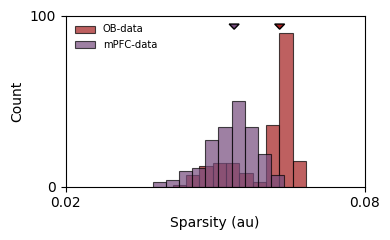

In [11]:
plot_xlim = [.02,.08]
plot_ylim = [0,100]
plot_trans = .7
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
fig_lw = figure_size[0]*.5
save_fig = 0

plt.figure(figsize=figure_size)

# plt.hist(sparsity_bt_shuff[chn_ob], color=color_ob_n, alpha=plot_trans-.3, label='OB-shuffled')
# plt.hist(sparsity_bt_shuff[chn_mpfc], color=color_mpfc_n, alpha=plot_trans-.3, label='mPFC-shuffled')

plt.hist(sparsity_bt[chn_ob], color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='OB-data')
plt.hist(sparsity_bt[chn_mpfc], color=color_mpfc_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='mPFC-data')

plt.arrow(np.nanmedian(sparsity_bt[chn_ob]), 95, 0, -.0001, head_length=3, head_width=.002, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(sparsity_bt[chn_mpfc]), 95, 0, -.0001, head_length=3, head_width=.002, ec=plot_edgecolor, color=color_mpfc_n)

plt.xlim(plot_xlim)
plt.xticks(plot_xlim)
plt.xlabel('Sparsity (au)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper left', fontsize=figure_size[0]*1.8)
clear_output()

if save_fig: plt.savefig(f'{FigDir}power_ml_sparsity_bt.svg')

# Further

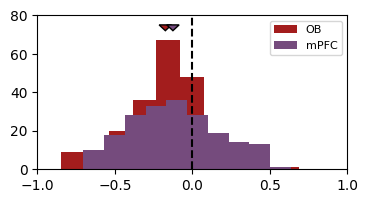

In [27]:
ax_cosine = np.zeros((num_chn,cycle_num)) * np.nan

for iCycle in range(cycle_num):
    ax_cosine[chn_ob,iCycle]   = cosine(freqwt_ob_wc[iCycle].reshape(1,-1), freqwt_ob_bt[iCycle].reshape(1,-1))
    ax_cosine[chn_mpfc,iCycle] = cosine(freqwt_mpfc_wc[iCycle].reshape(1,-1), freqwt_mpfc_bt[iCycle].reshape(1,-1))

plt.figure(figsize=(4,2))
plt.hist(ax_cosine[chn_ob], color=color_ob_n, label='OB')
plt.hist(ax_cosine[chn_mpfc], color=color_mpfc_n, label='mPFC')

plt.arrow(np.nanmedian(ax_cosine[chn_ob]), 75, 0, -.0001, head_length=3, head_width=.08, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(ax_cosine[chn_mpfc]), 75, 0, -.0001, head_length=3, head_width=.08, ec=plot_edgecolor, color=color_mpfc_n)

plt.axvline(0, ls='--', color='k')
plt.xlim([-1,1])
plt.ylim([0,80])
plt.legend(fontsize=8)

In [28]:
rand_dist_ob   = np.random.normal(loc=0, scale=np.nanstd(ax_cosine[chn_ob]), size=cycle_num)
rand_dist_mpfc = np.random.normal(loc=0, scale=np.nanstd(ax_cosine[chn_mpfc]), size=cycle_num)

comp_permute_p(ax_cosine[chn_mpfc], rand_dist_mpfc)

0.0005599888002239956

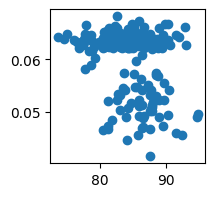

In [20]:
plt.figure(figsize=(2,2))
plt.scatter(acc_ob_bt,sparsity_bt[chn_ob])